# CME538 - Introduction to Data Science

## Assignment 7 - Email Spam Classification

### Learning Objectives

After completing this assignment, you should be able to:

- Formulate a binary classification problem from labelled data.
- Explore class distributions and identify potential class imbalance.
- Engineer numerical features from text data for classification.
- Fit logistic regression classifiers using scikit-learn.
- Interpret predicted class probabilities.
- Convert predicted probabilities into class predictions using a classification threshold.
- Evaluate classifiers using a confusion matrix, accuracy, precision, recall, and F1-score.
- Compare classifier performance using ROC and precision-recall curves.
- Use stratified cross-validation to estimate generalization performance.
- Tune logistic regression hyperparameters using cross-validation.
- Evaluate the effect of class imbalance on classifier performance.
- Compare alternative classification models using appropriate evaluation metrics.
- Build a reproducible classification workflow from feature engineering through final test evaluation.

### Marking Breakdown

| Question | Marks |
|---|---:|
| Question 1a | 1 |
| Question 1b | 2 |
| Question 1c | 1 |
| Question 2a | 1 |
| Question 2b | 1 |
| Question 2c | 2 |
| Question 3a | 1 |
| Question 3b | 1 |
| Question 3c | 2 |
| Question 4a | 1 |
| Question 4b | 2 |
| Question 5 | 2 |
| Question 6 | 2 |
| Question 7 | 2 |
| Question 8 | 3 |
| Question 9 | 3 |
| Code quality | 3 |
| **Total** | **30** |


### Code Quality

Code quality will be assessed across the complete notebook.

| Level | Points | Description |
|---|---:|---|
| **Developing** | 1 | Code produces the required results but may be difficult to follow, unnecessarily repetitive, poorly organized, or include excessive output. |
| **Competent** | 2 | Code is organized and readable, uses appropriate Pandas and scikit-learn operations, and produces concise, relevant outputs. |
| **Strong** | 3 | Code is clear, concise, well organized, and reproducible; uses Pandas and scikit-learn effectively; avoids unnecessary operations and output; and executes successfully from beginning to end. |

## Notebook Setup

In [1]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure notebook plots
%matplotlib inline
sns.set_theme(style="whitegrid", context="notebook")

# Overview

Every day, email providers need to decide which messages belong in your inbox and which should be sent to spam.

That decision is not always easy. A spam filter that is too permissive may fill your inbox with unwanted messages, while a filter that is too aggressive might hide an important email that you actually wanted to receive.

In this assignment, you will take on this real-world classification problem. Your goal is to build a model that can classify an email as **spam** or **not spam** using information contained in the email itself.

You will begin by exploring the emails and looking for patterns that might distinguish spam from legitimate messages. You will then turn those patterns into features, train a **logistic regression classifier**, and evaluate how well your model performs.

Along the way, you will investigate an important question:

> **What makes a good spam filter?**

A model with high accuracy is not necessarily a useful model. You will examine the mistakes your classifier makes, compare different evaluation metrics, and explore how the classification threshold affects the behaviour of your spam filter.

By the end of the assignment, you will have built and evaluated your own spam classifier using the same fundamental ideas that appear in real-world machine learning systems.

---

# The Data

The dataset for this assignment is stored in `emails.csv`. Each row represents an email that has been labelled as either **spam** or **not spam**.

The dataset contains the following variables:

- `id` — an identifier associated with the email
- `subject` — the subject line of the email
- `email` — the body text of the email
- `label` — the classification target:
  - `1` = spam
  - `0` = not spam

The dataset contains **7,513 emails**.

Before building our spam classifier, let's load the data and inspect a few observations.

In [2]:
# Load the email dataset
email_data = pd.read_csv("emails.csv", index_col=0)

# Preview the data
email_data.head()

,id,subject,email,label
4282,4282,Subject: RE: [ILUG] Dell GX260 V Redhat 7.3\r\n,> When I get a box I don't want any of that in...,0
6293,6293,Subject: IBM eNews: Aktuelle Informationen von...,IBM eNews\r\n 4. Juli 2002\r\n \r\n Liebe Lese...,0
2349,2349,"Subject: [zzzzteana] Height, weight, girth, et...","http://www.guardian.co.uk/uk_news/story/0,3604...",0
3786,3786,Subject: Re: The GOv gets tough on Net Users.....,Hire a really talented skywriter to doodle nud...,0
4731,4731,Subject: Lander risks missing Mars trip\r\n,"URL: http://www.newsisfree.com/click/-4,805285...",0


Each observation contains the raw text of an email along with its known classification.

Our goal will be to use information from the `subject` and `email` text to predict the `label`.

Before deciding how to build our classifier, we first need to understand the data we are working with.

---

# Data Cleaning and Preprocessing

Before exploring the emails, we will perform a small amount of data cleaning.

The same word can appear with different capitalization. For example, `FREE`, `Free`, and `free` have the same meaning for our purposes, but a computer may treat them as different strings.

To make our text comparisons consistent, we will convert both the `subject` and `email` columns to lowercase.

In [3]:
# Convert email subjects and bodies to lowercase
email_data["subject"] = email_data["subject"].str.lower()
email_data["email"] = email_data["email"].str.lower()

## Missing Values

Before building a model, we should check whether any observations contain missing information.

Missing values require some thought because their meaning depends on the variable. For example, a missing email subject may simply mean that the sender did not include a subject.

In [4]:
# Count missing values in each column
email_data.isna().sum()

id         0
subject    6
email      0
label      0
dtype: int64

There are **6 missing values** in `subject`, while the email body and target label are complete.

In this dataset, a missing subject means that the email did not contain a subject line. Since we will work with text, we can represent a missing subject using an empty string `""`.

We should not apply this strategy blindly to other variables. In particular, missing target labels would require different treatment because a model cannot learn from an observation whose correct classification is unknown.

In [5]:
# Replace missing text with an empty string
email_data[["subject", "email"]] = (
    email_data[["subject", "email"]]
    .fillna("")
)

# Verify that no missing values remain
email_data.isna().sum()

id         0
subject    0
email      0
label      0
dtype: int64

---

## Training and Test Sets

Before exploring features or building classifiers, we will separate the data into:

- a **training set**, which we will use for exploratory analysis, feature engineering, model development, and cross-validation; and
- a **test set**, which we will reserve for the final evaluation of our selected classifier.

The test set should not influence our feature choices, model selection, classification threshold, or other modelling decisions.

Because spam emails are less common than non-spam emails, we will use a **stratified split**. Stratification approximately preserves the proportion of spam and non-spam emails in both datasets.

We will use `random_state=0` so that the split is reproducible.

In [6]:
from sklearn.model_selection import train_test_split

# Split the data into training and test sets
train, test = train_test_split(
    email_data,
    test_size=0.20,
    random_state=0,
    stratify=email_data["label"]
)

print(f"Training observations: {len(train)}")
print(f"Test observations: {len(test)}")

Training observations: 6010
Test observations: 1503


We can verify that stratification approximately preserved the proportion of spam emails in both datasets.

In [7]:
# Compare the proportion of spam emails
print(
    f"Overall spam proportion: "
    f"{email_data['label'].mean():.1%}"
)

print(
    f"Training spam proportion: "
    f"{train['label'].mean():.1%}"
)

print(
    f"Test spam proportion: "
    f"{test['label'].mean():.1%}"
)

Overall spam proportion: 25.6%
Training spam proportion: 25.6%
Test spam proportion: 25.6%


The spam proportions are approximately the same across the full dataset, training set, and test set.

This will become important later because our classification problem is **imbalanced**: one class occurs considerably more often than the other.

For now, we will put the test set aside. From this point onward, our exploratory analysis and model development will use the **training data only**.

---

# 1. Feature Engineering

Our raw predictors are text, but a logistic regression model requires numerical features.

This means we need to convert useful characteristics of each email into numbers that a model can work with.

For example, we might ask whether an email:

- contains words commonly associated with spam,
- contains unusually promotional language,
- includes particular phrases or formatting patterns, or
- differs from legitimate email in other measurable ways.

This process is called **feature engineering**.

Rather than immediately choosing features, we will first inspect examples from the training data and look for patterns that might help distinguish spam from non-spam emails.

---

## Question 1a — Looking for Spam Signals

Below, we will inspect one non-spam email and one spam email from the training set.

Read both examples and identify at least **one characteristic** that might help distinguish spam from non-spam email.

Your idea should be something that could potentially be converted into a numerical feature.

In [8]:
# Display one non-spam and one spam email
example_index = 1

not_spam_example = (
    train.loc[
        train["label"] == 0,
        "email"
    ]
    .iloc[example_index]
)

spam_example = (
    train.loc[
        train["label"] == 1,
        "email"
    ]
    .iloc[example_index]
)

print("--------")
print("NOT SPAM")
print("--------")
print(not_spam_example)

print("\n----")
print("SPAM")
print("----")
print(spam_example)

--------
NOT SPAM
--------
on saturday, september 28, 2002, at 12:54 pm, gary lawrence murphy 
 wrote:
 
 > although it's like a total shock to 99.999% (5nines) of all the
 > employed website designers out there, the truth is webforms /can/
 > accept "u.s. of a" as a country.  incredible, but true.  web forms can
 > also accept /multiple/ or even /free-form/ telephone numbers and can
 > even be partitioned into manageable steps. all this can also be done
 > without selling exclusive rights to your wallet to the world's
 > second-richest corporation (assuming cisco is still #1) and vendor
 > locking your business into their "small transaction fee" tithe.
 
 yes, but this is what normally happened:
 
 engineer: we can put an input validator/parser on the backend to do 
 that.
 
 designer: there's a javascript library that can do some of the 
 pre-validation.
 
 creative director: i want it in blue, with a zooming logo.
 
 engineer: can we get to that later, we need to meet functional spe

**Q1a: Your answer:**

<!-- The spam example contains a lot of HTML formatting, including terms such as "html", "body", and "font", while the non-spam example mainly contains a written conversation. One possible numerical feature is a binary indicator for whether "html" appears in an email: 1 if it appears and 0 otherwise. This may help distinguish the classes, although legitimate emails can also contain HTML. -->


----

## 1.1 Detecting Words in Email Text

One simple way to represent text numerically is to record whether particular words appear in an email.

For example, suppose we want to detect the words:

`free`, `meeting`, and `money`

An email containing `free` and `money`, but not `meeting`, could be represented as:

| free | meeting | money |
|---:|---:|---:|
| 1 | 0 | 1 |

This is a simple **binary feature representation**:

- `1` means the word appears in the email,
- `0` means the word does not appear.

This representation ignores many aspects of language, but it gives us a transparent way to begin converting email text into numerical predictors.

----

## Question 1b — Create Word-Detection Features

Write a function named `word_detector()` that accepts:

- `words` — a list of words to search for, and
- `texts` — a Pandas Series containing email text.

The function should return a DataFrame where:

- each row corresponds to one email,
- each column corresponds to one word, and
- each value is `1` if the word appears in the email and `0` otherwise.

For example:

```python
word_detector(
    ["hello", "bye", "world"],
    pd.Series([
        "hello",
        "hello worldhello"
    ])
)
```


In [9]:
# Question 1b

def word_detector(words, texts):
    """Return binary indicators showing whether each word appears in each text."""
    
    word_features = pd.DataFrame(index=texts.index)

    for word in words:
        word_features[word] = (
            texts.str.contains(
                word,
                regex=False,
                na=False
            ).astype(int)
        )

    return word_features

In [10]:
# Test the function on a small example
word_detector(
    ["hello", "bye", "world"],
    pd.Series([
        "hello",
        "hello worldhello"
    ])
)

,hello,bye,world
0,1,0,0
1,1,0,1


In [18]:
# Apply the function to training emails
word_detector(
    ["hello", "bye", "world"],
    train["email"]
).head()

,hello,bye,world
639,0,0,0
3120,1,0,1
4771,0,0,1
2556,0,0,0
3426,0,0,0


In [11]:
# Verification - do not modify

word_detector_check = word_detector(
    ["hello", "bye", "world"],
    train["email"]
)

print(
    "Q1b Answer - Correct number of rows:",
    len(word_detector_check) == len(train)
)

print(
    "Correct columns:",
    word_detector_check.columns.tolist()
    == ["hello", "bye", "world"]
)

print(
    "Index preserved:",
    word_detector_check.index.equals(
        train.index
    )
)

print(
    "Only binary values:",
    word_detector_check
    .isin([0, 1])
    .all()
    .all()
)

Q1b Answer - Correct number of rows: True
Correct columns: True
Index preserved: True
Only binary values: True


----

## 1.2 Comparing Word Use Across Classes

A useful feature should help distinguish the two classes.

For a binary word feature, we can compare:

- the proportion of **spam** emails containing the word, and
- the proportion of **non-spam** emails containing the word.

If these proportions differ substantially, the word may contain useful information for classification.

For example, suppose the word `offer` appears in:

- 40% of spam emails, but
- only 5% of non-spam emails.

That difference suggests that `offer` may be an informative predictor.

However, a word does not need to occur more frequently in spam to be useful. A word that appears much more often in legitimate email could also help distinguish the classes.

---

## Question 1c — Explore Potential Word Features

Choose **six words** that you think may help distinguish spam from non-spam emails.

Using the **training data only**:

1. Create binary features for your six words using `word_detector()`.
2. Calculate or visualize the proportion of emails containing each word separately for spam and non-spam emails.
3. Create a grouped bar chart comparing the two classes.

Your plot should include:

- all six words,
- separate bars for spam and non-spam emails,
- appropriate axis labels, and
- a clear title.

Choose words whose occurrence patterns provide some evidence that they may be useful classification features.

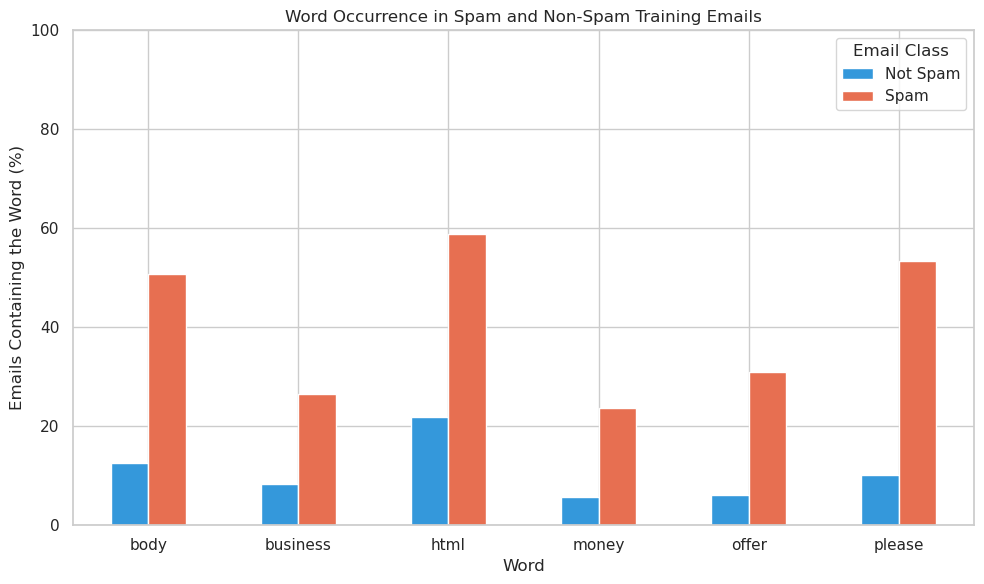

In [12]:
# Question 1c

# Choose six words that you think may help distinguish
# spam from non-spam emails.
candidate_words = ["body", "business", "html", "money", "offer", "please"]

candidate_word_features = word_detector(
    candidate_words,
    train["email"]
)

word_proportions = (
    candidate_word_features
    .groupby(train["label"])
    .mean()
    .T
    .rename(columns={
        0: "Not Spam",
        1: "Spam"
    })
    * 100
)

ax = word_proportions.plot(
    kind="bar",
    figsize=(10, 6),
    color=["#3498db", "#e76f51"]
)

ax.set_xlabel("Word")
ax.set_ylabel("Emails Containing the Word (%)")
ax.set_title("Word Occurrence in Spam and Non-Spam Training Emails")
ax.set_ylim(0, 100)
plt.xticks(rotation=0)
plt.legend(title="Email Class")
plt.tight_layout()
plt.show()

---

# 2. Building Our First Spam Classifier

We now have a way to convert selected words into numerical features.

Our next step is to use those features to train a **logistic regression classifier**.

Logistic regression estimates the probability that an observation belongs to the positive class. In this assignment:

- `0` = not spam
- `1` = spam

For an email with features \(X\), the classifier estimates:

$$
P(\text{spam} \mid X)
$$

We can then convert this probability into a class prediction using a classification threshold.

We will begin with a small set of word-based features so that we can clearly see how the classification workflow operates.

---

## Question 2a — Prepare the Classification Data

Consider the following five words:

```python
["drug", "bank", "prescription", "memo", "private"]
```

Use these words and the `train` DataFrame to create:

- `X_train` — a DataFrame of binary word features created using `word_detector()` on all emails in `train`.
- `y_train` — a Series containing the corresponding `label` values.

Each row of `X_train` should correspond to the same email as the label in `y_train`.


In [13]:
# Question 2a

model_words = [
    "drug",
    "bank",
    "prescription",
    "memo",
    "private"
]

# Create binary word features for the training emails
X_train = word_detector(model_words,train["email"])

# Select the corresponding target labels
y_train = train["label"].copy()

In [14]:
X_train.head()

,drug,bank,prescription,memo,private
639,0,0,0,0,0
3120,0,0,0,0,0
4771,0,0,0,0,0
2556,0,0,0,0,0
3426,0,0,0,0,0


In [15]:
y_train.head()

639     0
3120    1
4771    0
2556    0
3426    0
Name: label, dtype: int64

In [16]:
# Verification - do not modify

print(
    "Q2a Answer - Number of training observations:",
    len(X_train)
)

print(
    "Predictors and target have equal length:",
    len(X_train) == len(y_train)
)

print(
    "Correct predictor columns:",
    X_train.columns.tolist() == model_words
)

print(
    "Target contains only 0 and 1:",
    set(y_train.unique()).issubset({0, 1})
)

Q2a Answer - Number of training observations: 6010
Predictors and target have equal length: True
Correct predictor columns: True
Target contains only 0 and 1: True


---

## Question 2b — Fit a Logistic Regression Classifier

Create a `LogisticRegression` classifier named `spam_model`.

Fit the classifier using `X_train` and `y_train`.

Then create:

- `y_train_predicted` — the predicted class for each training email
- `y_train_probability` — the predicted probability that each training email is spam

Use `predict()` for class predictions and `predict_proba()` for probabilities.

In [17]:
from sklearn.linear_model import LogisticRegression

# Question 2b

# Create the logistic regression classifier
spam_model = LogisticRegression(max_iter=1000,random_state=0)

# Fit the classifier using the training features and labels
spam_model.fit(X_train, y_train)

# Predict the class for each training email
y_train_predicted = spam_model.predict(X_train)

# Predict the probability that each training email is spam
y_train_probability = spam_model.predict_proba(X_train)[:, 1]

In [18]:
# Verification - do not modify

print(
    "Q2b Answer - Model fitted:",
    hasattr(spam_model, "classes_")
)

print(
    "Number of class predictions:",
    len(y_train_predicted)
)

print(
    "Number of probability predictions:",
    len(y_train_probability)
)

print(
    "All probabilities between 0 and 1:",
    (
        (y_train_probability >= 0)
        & (y_train_probability <= 1)
    ).all()
)

Q2b Answer - Model fitted: True
Number of class predictions: 6010
Number of probability predictions: 6010
All probabilities between 0 and 1: True


---

## 2.1 Predicted Probabilities

Logistic regression does not fundamentally produce only `0` or `1`.

For each email, it estimates the probability of belonging to each class.

Because our classes are:

- `0` = not spam
- `1` = spam

we can inspect the order of the probability columns using the classifier's `classes_` attribute.


In [19]:
# Check the order of the classes
spam_model.classes_

array([0, 1])

In [20]:
# Display the first five probability predictions
spam_model.predict_proba(X_train)[:5]

array([[0.76446725, 0.23553275],
       [0.76446725, 0.23553275],
       [0.76446725, 0.23553275],
       [0.76446725, 0.23553275],
       [0.76446725, 0.23553275]])

Each row contains two probabilities:

$$
P(\text{not spam} \mid X)
$$

and

$$
P(\text{spam} \mid X)
$$

Since the two classes cover all possible outcomes, the probabilities in each row sum to 1.

The second column corresponds to the probability that the email is spam, which we stored earlier in `y_train_probability`.

In [21]:
# Inspect the first ten spam probabilities
y_train_probability[:10]

array([0.23553275, 0.23553275, 0.23553275, 0.23553275, 0.23553275,
       0.23553275, 0.23553275, 0.23553275, 0.23553275, 0.23553275])

----

## Question 2c — Build a Classifier Using Your Own Word Features

In Question 1c, you selected six words whose occurrence patterns appeared to differ between spam and non-spam emails.

Now use those features to build a second logistic regression classifier.

Using the six words selected in Question 1c:

1. Create a feature matrix named `X_train_candidate`.
2. Create a logistic regression classifier named `candidate_model`.
3. Fit the model using the training data.
4. Create class predictions named `y_train_candidate_predicted`.
5. Create predicted spam probabilities named `y_train_candidate_probability`.

Later, we will compare this classifier with our original five-word model using cross-validation.

In [22]:
# Question 2c

# Create the six-word feature matrix using the words
# selected in Question 1c.
X_train_candidate = word_detector(candidate_words,train["email"])

# Create a logistic regression classifier
candidate_model = LogisticRegression(max_iter=1000,random_state=0)


# Fit the model using the training data
candidate_model.fit(X_train_candidate,y_train)

# Generate class predictions
y_train_candidate_predicted = candidate_model.predict(X_train_candidate)

# Generate predicted probabilities for spam
y_train_candidate_probability = candidate_model.predict_proba(X_train_candidate)[:, 1]

In [23]:
# Verification - do not modify

print(
    "Q2c Answer - Correct number of observations:",
    len(X_train_candidate) == len(y_train)
)

print(
    "Six predictors used:",
    X_train_candidate.shape[1] == 6
)

print(
    "Candidate model fitted:",
    hasattr(candidate_model, "classes_")
)

print(
    "All probabilities are valid:",
    (
        (y_train_candidate_probability >= 0)
        & (y_train_candidate_probability <= 1)
    ).all()
)

Q2c Answer - Correct number of observations: True
Six predictors used: True
Candidate model fitted: True
All probabilities are valid: True


---

# 3. Evaluating a Classifier

Before deciding whether our classifier is useful, we need to decide how to evaluate it.

A natural starting point is **accuracy**:

$$
\text{Accuracy}
=
\frac{\text{Number of Correct Predictions}}
{\text{Total Number of Predictions}}
$$

Let's calculate the training accuracy of our first classifier.

In [24]:
from sklearn.metrics import accuracy_score

training_accuracy = accuracy_score(
    y_train,
    y_train_predicted
)

print(
    f"Training accuracy: "
    f"{training_accuracy:.3f}"
)

Training accuracy: 0.758


At first glance, this may appear to be reasonably good performance.

However, our dataset is **imbalanced**: non-spam emails are much more common than spam emails.

This raises an important question:

> Could we obtain high accuracy without learning anything useful about spam?

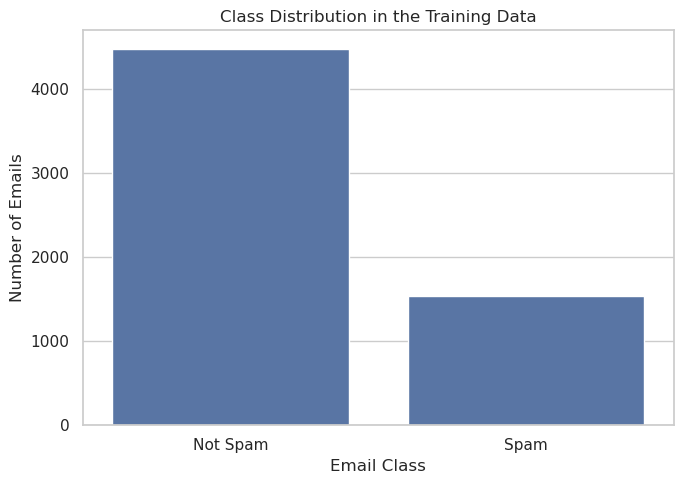

In [25]:
# Visualize the class distribution in the training data
class_counts = (
    train["label"]
    .map({
        0: "Not Spam",
        1: "Spam"
    })
)

plt.figure(figsize=(7, 5))

sns.countplot(
    x=class_counts,
    order=["Not Spam", "Spam"]
)

plt.xlabel("Email Class")
plt.ylabel("Number of Emails")
plt.title("Class Distribution in the Training Data")

plt.tight_layout()
plt.show()

Approximately three quarters of the training emails are not spam.

This means that a classifier could achieve relatively high accuracy simply by predicting **not spam for every email**.

To see why this matters, we will compare our logistic regression model with a simple majority-class baseline.

---

## Question 3a — Build a Majority-Class Baseline

Create a NumPy array named `majority_predictions` that predicts `0` for every observation in `y_train`.

Then calculate its training accuracy and store the result in `majority_accuracy`.

In [26]:
# Question 3a

# Create predictions that always predict the majority class (0 = not spam)
majority_predictions = np.zeros(len(y_train),dtype=int)


# Calculate the accuracy of the majority-class baseline
majority_accuracy = accuracy_score(y_train,majority_predictions)

print(
    f"Logistic regression accuracy: "
    f"{training_accuracy:.3f}"
)

print(
    f"Majority-class accuracy: "
    f"{majority_accuracy:.3f}"
)

Logistic regression accuracy: 0.758
Majority-class accuracy: 0.744


In [27]:
# Verification - do not modify

print(
    "Q3a Answer - Correct number of predictions:",
    len(majority_predictions) == len(y_train)
)

print(
    "Baseline predicts only class 0:",
    np.all(majority_predictions == 0)
)

Q3a Answer - Correct number of predictions: True
Baseline predicts only class 0: True


The majority-class classifier can achieve fairly high accuracy despite making **no attempt to identify spam**.

This does not mean that accuracy is useless. Instead, it shows that **accuracy alone can be misleading when the classes are imbalanced**.

To understand classifier performance more completely, we need to examine the types of errors the model makes.

---

## 3.1 The Confusion Matrix

For binary classification, every prediction belongs to one of four categories.

| | Predicted Not Spam | Predicted Spam |
|---|---:|---:|
| **Actual Not Spam** | True Negative (TN) | False Positive (FP) |
| **Actual Spam** | False Negative (FN) | True Positive (TP) |

For our spam-filtering problem:

- **True Negative (TN)** — a legitimate email correctly reaches the inbox.
- **False Positive (FP)** — a legitimate email is incorrectly sent to spam.
- **False Negative (FN)** — a spam email incorrectly reaches the inbox.
- **True Positive (TP)** — a spam email is correctly identified as spam.

These errors do not necessarily have the same consequences.

For example, incorrectly hiding an important legitimate email may be more costly than allowing an unwanted advertisement into the inbox.

---

## Question 3b — Examine the Confusion Matrix

Use `confusion_matrix()` to calculate the confusion matrix for `spam_model` using its training predictions.

Store the result in `training_confusion_matrix`.

Then display the matrix using `ConfusionMatrixDisplay`.

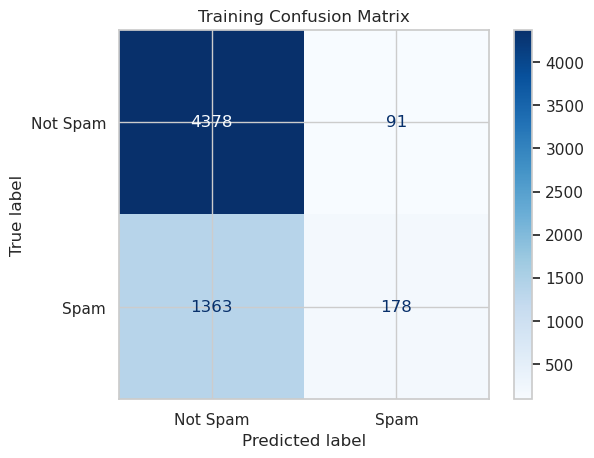

In [28]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Question 3b

# Calculate the confusion matrix
training_confusion_matrix = confusion_matrix(y_train, y_train_predicted,labels=[0, 1])

# Create the confusion-matrix display
display = ConfusionMatrixDisplay(
    confusion_matrix=training_confusion_matrix,
    display_labels=[
        "Not Spam",
        "Spam"
    ]
)

# Display the confusion matrix
display.plot(cmap="Blues",values_format="d")

plt.title(
    "Training Confusion Matrix"
)

plt.show()

In [29]:
# Verification - do not modify

print(
    "Q3b Answer - Confusion matrix shape:",
    training_confusion_matrix.shape
)

print(
    "All training observations represented:",
    training_confusion_matrix.sum()
    == len(y_train)
)

Q3b Answer - Confusion matrix shape: (2, 2)
All training observations represented: True


---

## 3.2 Precision, Recall, and F1-Score

The confusion matrix allows us to calculate several useful classification metrics.

### Precision

Precision asks:

> Of the emails predicted to be spam, how many were actually spam?

$$
\text{Precision}
=
\frac{TP}{TP+FP}
$$

High precision means that when the model labels an email as spam, it is usually correct.

### Recall

Recall asks:

> Of all the emails that were actually spam, how many did the model detect?

$$
\text{Recall}
=
\frac{TP}{TP+FN}
$$

High recall means that the model catches most spam emails.

### F1-score

The F1-score combines precision and recall using their harmonic mean:

$$
F_1
=
2
\frac{
\text{Precision}\times\text{Recall}
}{
\text{Precision}+\text{Recall}
}
$$

F1 is useful when we care about balancing precision and recall.

---

## Question 3c — Evaluate the First Classifier

Calculate the following training metrics for `spam_model`:

- accuracy
- precision
- recall
- F1-score

Store the results in:

- `training_accuracy`
- `training_precision`
- `training_recall`
- `training_f1`

Treat `1` (spam) as the positive class.

In [30]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

# Question 3c

# Calculate training accuracy
training_accuracy = accuracy_score(y_train,y_train_predicted)

# Calculate precision for the spam class
training_precision = precision_score(y_train,y_train_predicted,pos_label=1,zero_division=0)

# Calculate recall for the spam class
training_recall = recall_score(y_train,y_train_predicted,pos_label=1,zero_division=0)

# Calculate F1-score
training_f1 = f1_score(y_train,y_train_predicted,pos_label=1,zero_division=0)

print(
    f"Accuracy:  {training_accuracy:.3f}"
)

print(
    f"Precision: {training_precision:.3f}"
)

print(
    f"Recall:    {training_recall:.3f}"
)

print(
    f"F1-score:  {training_f1:.3f}"
)

Accuracy:  0.758
Precision: 0.662
Recall:    0.116
F1-score:  0.197


These metrics describe different aspects of classifier performance.

A spam filter with high recall but low precision may catch most spam but also hide many legitimate emails.

A spam filter with high precision but low recall may be very reliable when it flags spam, but allow many spam messages through.

Which trade-off is preferable depends on the application and the relative cost of different errors.

---

# 4. Predicted Probabilities and Classification Thresholds

So far, we have used `predict()` to convert each email directly into a class:

- `0` = not spam
- `1` = spam

However, logistic regression first estimates a **probability** that an observation belongs to the positive class.

For each email, our model estimates:

$$
P(\text{spam} \mid X)
$$

The class prediction is then determined using a **classification threshold**.

By default, scikit-learn uses a threshold of `0.50`:

$$
P(\text{spam} \mid X) \geq 0.50
\Rightarrow
\text{predict spam}
$$

Changing the threshold changes the behaviour of the classifier.

A lower threshold makes the model more willing to classify an email as spam, while a higher threshold makes it more conservative.

---

## Question 4a — Create Predictions Using Different Thresholds

Using `y_train_probability`, create class predictions using the following thresholds:

- `0.30`
- `0.50`
- `0.70`

Store the predictions in:

- `predictions_030`
- `predictions_050`
- `predictions_070`

Each variable should contain a NumPy array of `0` and `1` values.

In [32]:
# Question 4a

# Create predictions using a threshold of 0.30
predictions_030 = (y_train_probability >= 0.30).astype(int)

# Create predictions using a threshold of 0.50
predictions_050 = (y_train_probability >= 0.50).astype(int)

# Create predictions using a threshold of 0.70
predictions_070 = (y_train_probability >= 0.70).astype(int)

In [33]:
# Verification - do not modify

print(
    "Q4a Answer - Correct number of predictions:",
    len(predictions_030) == len(y_train)
    and len(predictions_050) == len(y_train)
    and len(predictions_070) == len(y_train)
)

print(
    "All predictions are binary:",
    set(np.unique(predictions_030)).issubset({0, 1})
    and set(np.unique(predictions_050)).issubset({0, 1})
    and set(np.unique(predictions_070)).issubset({0, 1})
)

Q4a Answer - Correct number of predictions: True
All predictions are binary: True


---

## Question 4b — Compare the Precision–Recall Trade-off

Calculate the precision and recall of the classifier at thresholds:

- `0.30`
- `0.50`
- `0.70`

Create a DataFrame named `threshold_results` with the columns:

- `threshold`
- `precision`
- `recall`

Then display the DataFrame.

Based on the results, explain how increasing the threshold affects precision and recall.

For a spam-filtering application, briefly discuss why a user might prefer a lower or higher threshold.

In [34]:
# Question 4b

threshold_results = pd.DataFrame({
    "threshold": [
        0.30,
        0.50,
        0.70
    ],
    "precision": [
        precision_score(
            y_train,
            predictions_030,
            zero_division=0
        ),
        precision_score(
            y_train,
            predictions_050,
            zero_division=0
        ),
        precision_score(
            y_train,
            predictions_070,
            zero_division=0
        )
    ],
    "recall": [
        recall_score(
            y_train,
            predictions_030,
            zero_division=0
        ),
        recall_score(
            y_train,
            predictions_050,
            zero_division=0
        ),
        recall_score(
            y_train,
            predictions_070,
            zero_division=0
        )
    ]
})

threshold_results

,threshold,precision,recall
0,0.3,0.565476,0.184945
1,0.5,0.661710,0.115509
2,0.7,0.800000,0.041531


**Your answer: Increasing the threshold from 0.30 to 0.70 raises precision from approximately 0.565 to 0.800, while recall falls from approximately 0.185 to 0.042. The classifier becomes more selective about which emails it labels as spam, so it catches fewer spam messages. A user might prefer a lower threshold to catch more spam and reduce false negatives. However, this can also send more legitimate emails to the spam folder. A higher threshold may be preferable when missing an important legitimate email would be costly. It reduces the risk of false positives, but allows more spam into the inbox.**

<!--
Describe how increasing the classification threshold affects precision and recall.

Then explain why a user of a spam filter might prefer:

- a lower classification threshold, or
- a higher classification threshold.

Relate your explanation to the consequences of false positives and false negatives.
-->

---

# 5. Visual Evaluation of Classifiers

A single classification threshold gives us only one view of classifier performance.

Instead, we can evaluate the model over many possible thresholds.

Two useful visual tools are:

- the **Receiver Operating Characteristic (ROC) curve**, and
- the **Precision–Recall curve**.

These curves use the predicted probabilities rather than only the final class predictions.

---

## ROC Curve

The ROC curve plots:

- **True Positive Rate (Recall)** on the y-axis
- **False Positive Rate** on the x-axis

for many different classification thresholds.

The **ROC-AUC** summarizes the curve using a single number.

A model with stronger ability to distinguish spam from non-spam will generally have a larger ROC-AUC.

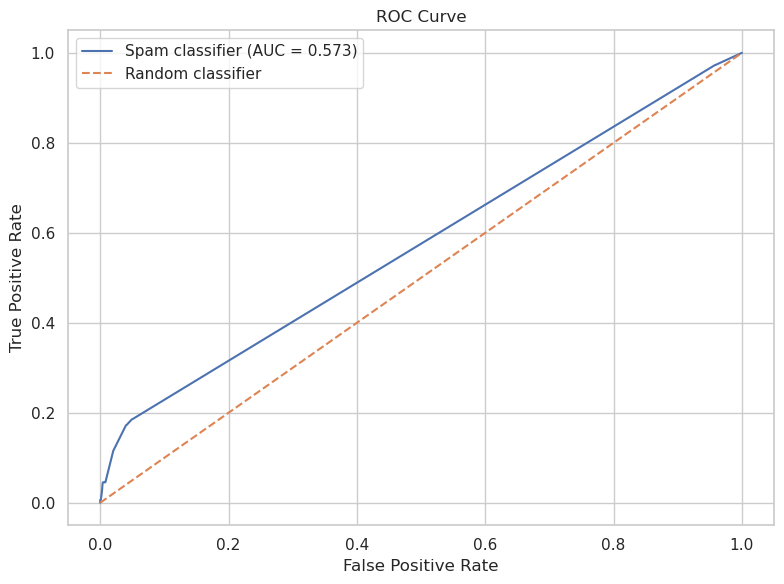

In [35]:
from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

# Calculate the ROC curve
fpr, tpr, roc_thresholds = roc_curve(
    y_train,
    y_train_probability
)

training_roc_auc = roc_auc_score(
    y_train,
    y_train_probability
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Spam classifier (AUC = {training_roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()

plt.tight_layout()
plt.show()

---

## Precision–Recall Curve

For an imbalanced classification problem, the precision–recall curve can be especially informative.

It shows how:

- **precision**, and
- **recall**

change as the classification threshold varies.

The **average precision** score summarizes performance across the precision–recall curve.

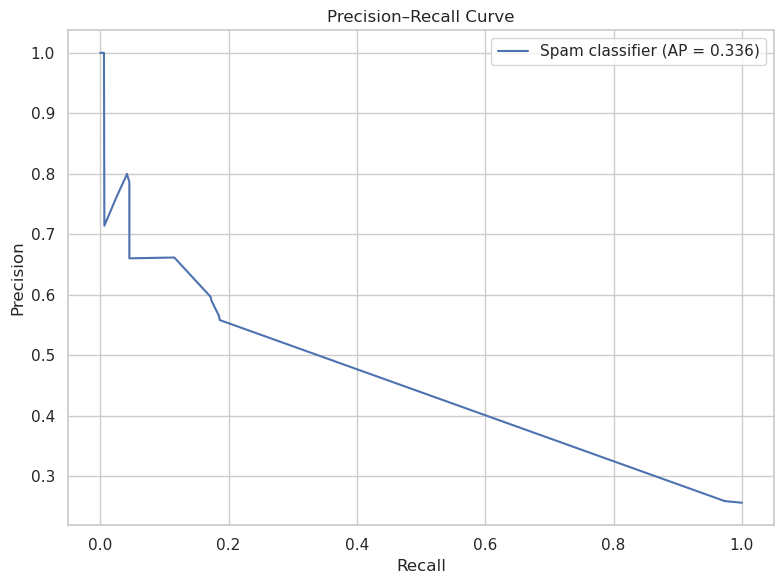

In [36]:
# Calculate precision and recall across thresholds
pr_precision, pr_recall, pr_thresholds = (
    precision_recall_curve(
        y_train,
        y_train_probability
    )
)

training_average_precision = (
    average_precision_score(
        y_train,
        y_train_probability
    )
)

plt.figure(figsize=(8, 6))

plt.plot(
    pr_recall,
    pr_precision,
    label=(
        "Spam classifier "
        f"(AP = {training_average_precision:.3f})"
    )
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve")
plt.legend()

plt.tight_layout()
plt.show()

---

## Question 5 — Interpreting Visual Classification Metrics

Using the ROC curve and precision–recall curve above:

1. Describe what the curves suggest about the classifier's ability to distinguish spam from non-spam emails.
2. Explain why evaluating the model over many thresholds provides more information than reporting accuracy alone.
3. Explain why the precision–recall curve is particularly useful for this dataset.

Do not use the test set when answering this question.

**Your answer: 
1. The ROC-AUC is approximately 0.573, suggesting that the original five-word classifier has limited ability to distinguish spam from non-spam. Its average precision is approximately 0.336. These results show some predictive information, but the classifier still misses much of the spam. 
2. Evaluating multiple thresholds shows how the balance between detecting spam and incorrectly flagging legitimate emails changes. Accuracy at one threshold does not show this trade-off or distinguish between false positives and false negatives. 
3. The precision–recall curve is useful because only about 25.6% of the training emails are spam. Predicting every email as non-spam would already produce about 74.4% accuracy. Precision and recall focus on how reliably the model identifies spam and how much spam it detects.**

<!--
1. Describe what the ROC and precision–recall curves suggest about the classifier's ability to distinguish spam from non-spam emails.

2. Explain why evaluating the classifier over many thresholds provides more information than accuracy alone.

3. Explain why the precision–recall curve is particularly useful for this dataset.
-->

---

# 6. Cross-Validation and Generalization

The metrics above were calculated using the same training data used to fit the model.

Training performance can be optimistic because the model has already seen those observations.

To estimate how well the classifier may perform on unseen data, we will use **cross-validation**.

Because our target is imbalanced, we will use **StratifiedKFold** rather than ordinary K-fold cross-validation.

Stratification helps preserve approximately the same proportion of spam and non-spam observations in each fold.

---

## Question 6 — Compare Models Using Stratified Cross-Validation

Training performance alone is not enough to determine which classifier is better.

Use **5-fold stratified cross-validation** to compare:

- `spam_model` — the original classifier based on five provided words
- `candidate_model` — the classifier based on the six words investigated in Question 1c

Evaluate both models using:

- accuracy
- precision
- recall
- F1-score
- ROC-AUC

Use:

```python
StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=0
)
```

Store the cross-validation results in:

- `baseline_cv_results`
- `candidate_cv_results`

Then create a DataFrame named `cv_comparison` showing the **mean** value of each metric for both models.

Use the cross-validation results to determine which feature set should be carried forward for further model development.


In [37]:
from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate
)

# Question 6

# Create a 5-fold stratified cross-validation object
stratified_cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=0)


# Define the evaluation metrics
scoring = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc"
]

# Evaluate the original five-word model
baseline_cv_results = cross_validate(spam_model,X_train,y_train,cv=stratified_cv,scoring=scoring)

# Evaluate the six-word candidate model
candidate_cv_results = cross_validate(candidate_model,X_train_candidate,y_train,cv=stratified_cv,scoring=scoring)

# Create a DataFrame containing the mean
# cross-validation performance of both models
cv_comparison = pd.DataFrame({
    "Baseline": {
        metric: baseline_cv_results[f"test_{metric}"].mean()
        for metric in scoring
    },
    "Candidate": {
        metric: candidate_cv_results[f"test_{metric}"].mean()
        for metric in scoring
    }
}).T

cv_comparison.round(3)

,accuracy,precision,recall,f1,roc_auc
Baseline,0.758,0.665,0.116,0.197,0.573
Candidate,0.821,0.715,0.503,0.589,0.851


**Your answer: The six-word candidate model performs better across all five cross-validation metrics. Its mean accuracy is approximately 0.821, compared with 0.758 for the baseline. Precision increases from approximately 0.665 to 0.715, while recall increases from approximately 0.116 to 0.503. The candidate model also has a higher mean F1-score, approximately 0.589 compared with 0.197, and a higher ROC-AUC, approximately 0.851 compared with 0.573. I would carry forward the six-word feature set because it detects substantially more spam while also improving precision. This decision uses cross-validation on the training data.**

<!--
Compare the cross-validation performance of the baseline and candidate models.

Consider the different metrics rather than accuracy alone.

Which feature set appears stronger overall?

Briefly explain which feature set you would carry forward for the next stage of model development.
-->


In [38]:
# Select the feature set with the higher mean cross-validation F1-score

baseline_mean_f1 = baseline_cv_results["test_f1"].mean()

candidate_mean_f1 = candidate_cv_results["test_f1"].mean()

if candidate_mean_f1 > baseline_mean_f1:
    selected_words = candidate_words.copy()
else:
    selected_words = model_words.copy()

# Create the selected training feature matrix
X_train_selected = word_detector(selected_words,train["email"])

y_train_selected = train["label"].copy()

print("Selected words:", selected_words)

Selected words: ['body', 'business', 'html', 'money', 'offer', 'please']


In [39]:
# Verification - do not modify

print(
    "Q6 Answer - Both models evaluated with five folds:",
    len(baseline_cv_results["test_f1"]) == 5
    and len(candidate_cv_results["test_f1"]) == 5
)

print(
    "Selected feature set is valid:",
    selected_words in [
        model_words,
        candidate_words
    ]
)

Q6 Answer - Both models evaluated with five folds: True
Selected feature set is valid: True


---

# 7. Improving the Spam Classifier

Our first classifier used only five binary word indicators.

That makes the model easy to understand, but it also severely limits the information available to the classifier.

We will now investigate whether the model can be improved while staying within the logistic regression framework.

There are several possible directions:

- choose more informative words;
- engineer additional properties of the email;
- include information from the subject line;
- change the amount of regularization;
- account for class imbalance.

For this assignment, we will focus on model tuning and class imbalance.

---

## 7.1 Tuning Logistic Regression

Logistic regression includes a hyperparameter named `C`.

`C` controls the strength of regularization:

- smaller `C` → stronger regularization
- larger `C` → weaker regularization

Rather than choosing a value arbitrarily, we can compare several candidate values using cross-validation.

We will use F1-score as the model-selection metric because it balances precision and recall.

---

## Question 7 — Tune the Selected Classifier

You have now selected a feature set using cross-validation.

Logistic regression includes a hyperparameter named `C`, which controls the strength of regularization:

- smaller `C` → stronger regularization
- larger `C` → weaker regularization

Use `GridSearchCV` to compare:

```python
[0.01, 0.1, 1, 10, 100]
```

Use:

- `X_train_selected`
- `y_train_selected`
- the `stratified_cv` object created earlier
- F1-score as the model-selection metric

Store the fitted search object in `grid_search`.

Then report the best value of `C` and the corresponding mean cross-validation F1-score.


In [40]:
from sklearn.model_selection import GridSearchCV

# Question 7

# Define the values of C to compare
parameter_grid = {
    "C": [
        0.01,
        0.1,
        1,
        10,
        100
    ]
}

# Create the grid search using logistic regression,
# F1-score, and the stratified cross-validation object
grid_search = GridSearchCV(
    estimator=LogisticRegression(
        max_iter=1000,
        random_state=0
    ),
    param_grid=parameter_grid,
    scoring="f1",
    cv=stratified_cv
)

# Fit the grid search using the selected training features
grid_search.fit(X_train_selected,y_train_selected)

# Report the best value of C
print(
    "Best C:",
    grid_search.best_params_["C"]
)

# Report the corresponding mean cross-validation F1-score
print(
    "Best mean CV F1-score:",
    f"{grid_search.best_score_:.3f}"
)

Best C: 1
Best mean CV F1-score: 0.589


In [41]:
# Verification - do not modify

print(
    "Q7 Answer - Best C is one of the candidates:",
    grid_search.best_params_["C"]
    in parameter_grid["C"]
)

print(
    "Best CV F1-score is valid:",
    0 <= grid_search.best_score_ <= 1
)

Q7 Answer - Best C is one of the candidates: True
Best CV F1-score is valid: True


---

# 8. Class Imbalance

Our training data contain substantially more non-spam emails than spam emails.

One way to make logistic regression place more emphasis on the minority class is to use:

```python
class_weight="balanced"
```

This automatically assigns greater weight to observations from the less common class.

The goal is not necessarily to increase accuracy. Instead, class weighting can change the balance between precision and recall by making errors on the minority class more influential during model fitting.

---

## Question 8 — Compare Standard and Balanced Logistic Regression

Using the best value of `C` identified in Question 7, compare:

- a standard tuned logistic regression model, and
- a logistic regression model with `class_weight="balanced"`.

Evaluate both models using **5-fold stratified cross-validation**.

Compare their mean:

- precision
- recall
- F1-score

Then select the model that you would use as the final classifier.

In [42]:
# Question 8

# Get the best value of C from Question 7
best_c = grid_search.best_params_["C"]

# Create a standard tuned logistic regression model
tuned_model = LogisticRegression(C=best_c,max_iter=1000,random_state=0)

# Create a tuned logistic regression model that
# accounts for class imbalance
balanced_model = LogisticRegression(C=best_c,class_weight="balanced",max_iter=1000,random_state=0)

# Metrics used to compare the two models
comparison_scoring = [
    "precision",
    "recall",
    "f1"
]

# Evaluate the standard tuned model
tuned_cv = cross_validate(
    tuned_model,
    X_train_selected,
    y_train_selected,
    cv=stratified_cv,
    scoring=comparison_scoring
)

# Evaluate the balanced model
balanced_cv = cross_validate(
    balanced_model,
    X_train_selected,
    y_train_selected,
    cv=stratified_cv,
    scoring=comparison_scoring
)

# Create a table containing the mean CV results
model_comparison = pd.DataFrame({
    "Standard": {
        metric: tuned_cv[f"test_{metric}"].mean()
        for metric in comparison_scoring
    },
    "Balanced": {
        metric: balanced_cv[f"test_{metric}"].mean()
        for metric in comparison_scoring
    }
}).T

model_comparison.round(3)

,precision,recall,f1
Standard,0.715,0.503,0.589
Balanced,0.616,0.771,0.684


In [43]:
# Select the final model using mean cross-validation F1-score

tuned_mean_f1 = tuned_cv["test_f1"].mean()

balanced_mean_f1 = balanced_cv["test_f1"].mean()

if balanced_mean_f1 > tuned_mean_f1:
    final_model = balanced_model
else:
    final_model = tuned_model

print(
    "Selected final model:",
    type(final_model).__name__
)

print(
    "Uses balanced class weights:",
    final_model.class_weight == "balanced"
)

Selected final model: LogisticRegression
Uses balanced class weights: True


**Your answer: The balanced model increases mean cross-validation recall from approximately 0.503 to 0.771, but precision decreases from approximately 0.715 to 0.616. Giving greater weight to the spam class helps the model detect more spam, but also causes more legitimate emails to be incorrectly flagged. The mean F1-score increases from approximately 0.589 to 0.684. I selected the balanced model because it has the higher cross-validation F1-score, which is the selection criterion used in this assignment. The trade-off is that users would need to check their spam folder more carefully for legitimate messages.**

<!-- Compare the precision, recall, and F1-score of the standard and balanced models. Describe the trade-off you observe. -->

---

# 9. Final Evaluation on the Test Set

Model development is now complete.

Up to this point, we have used the training data to:

- engineer features,
- compare feature sets,
- evaluate classifiers,
- examine probability thresholds,
- perform cross-validation,
- tune regularization, and
- investigate class imbalance.

The held-out test set has not been used to select features, tune hyperparameters, or compare candidate models.

We can now evaluate the selected classifier once on unseen data.

## Question 9 — Final Test-Set Evaluation

Prepare the test predictors using the same features selected during model development.

Then:

1. Create `X_test` and `y_test`.
2. Fit `final_model` using all selected training data.
3. Generate class predictions.
4. Generate predicted spam probabilities.
5. Calculate accuracy, precision, recall, F1-score, and ROC-AUC.
6. Create a confusion matrix.

Do not modify the model after examining the test-set results.

In [44]:
# Question 9

# Create the test feature matrix using the same
# features selected during model development
X_test = word_detector(selected_words,test["email"])

# Create the test target
y_test = test["label"].copy()

# Fit the selected final classifier using all selected training data
final_model.fit(X_train_selected,y_train_selected)

# Generate class predictions
y_test_predicted = final_model.predict(X_test)

# Generate predicted probabilities for the spam class
y_test_probability = final_model.predict_proba(X_test)[:, 1]

In [45]:
# Calculate final test metrics

test_accuracy = accuracy_score(y_test,y_test_predicted)

test_precision = precision_score(y_test,y_test_predicted,pos_label=1,zero_division=0)

test_recall = recall_score(y_test,y_test_predicted,pos_label=1,zero_division=0)

test_f1 = f1_score(y_test,y_test_predicted,pos_label=1,zero_division=0)


test_roc_auc = roc_auc_score(y_test,y_test_probability)

print(
    f"Test accuracy:  {test_accuracy:.3f}"
)

print(
    f"Test precision: {test_precision:.3f}"
)

print(
    f"Test recall:    {test_recall:.3f}"
)

print(
    f"Test F1-score:  {test_f1:.3f}"
)

print(
    f"Test ROC-AUC:   {test_roc_auc:.3f}"
)

Test accuracy:  0.828
Test precision: 0.635
Test recall:    0.769
Test F1-score:  0.696
Test ROC-AUC:   0.853


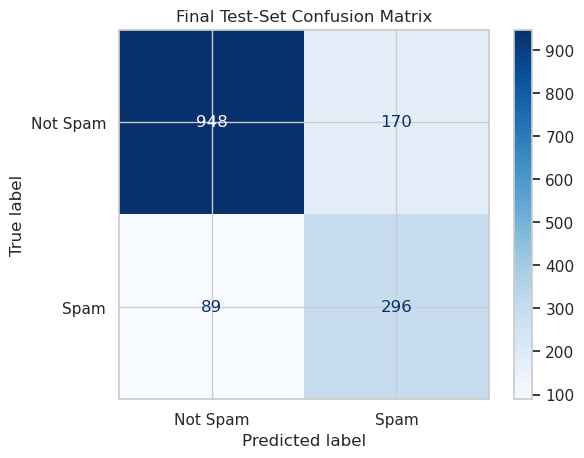

In [46]:
# Create the final test confusion matrix

final_confusion_matrix = confusion_matrix(y_test,y_test_predicted,labels=[0, 1])

display = ConfusionMatrixDisplay(
    confusion_matrix=final_confusion_matrix,
    display_labels=[
        "Not Spam",
        "Spam"
    ]
)

# Display the confusion matrix
display.plot(cmap="Blues",values_format="d")

plt.title(
    "Final Test-Set Confusion Matrix"
)

plt.show()

In [47]:
# Verification - do not modify

print(
    "Q9 Answer - Predictions match test observations:",
    len(y_test_predicted) == len(y_test)
)

print(
    "All probabilities are valid:",
    (
        (y_test_probability >= 0)
        & (y_test_probability <= 1)
    ).all()
)

print(
    "All test observations represented:",
    final_confusion_matrix.sum()
    == len(y_test)
)

Q9 Answer - Predictions match test observations: True
All probabilities are valid: True
All test observations represented: True


---

### Final Reflection

**Your answer: The final test F1-score is approximately 0.696, which is close to the selected model's mean cross-validation F1-score of 0.684. Test precision and recall are also close to their cross-validation values, suggesting similar performance on this held-out split. Test precision is approximately 0.635, meaning that about 63.5% of emails flagged as spam are actually spam. Recall is approximately 0.769, meaning that the classifier detects about 76.9% of the actual spam emails. The confusion matrix contains 948 true negatives, 170 false positives, 89 false negatives, and 296 true positives. The model catches most spam, but incorrectly sends 170 legitimate emails to the spam folder. These false positives could be costly if users miss important messages. The 89 false negatives represent spam that still reaches the inbox. A possible future improvement would be to use a larger vocabulary and include subject-line information. TF-IDF features could capture more detail than six binary word indicators. These alternatives should be assessed through cross-validation during future model development.**

<!--
Compare the final test results with the cross-validation results from model development.

Discuss the classifier's precision and recall and what these metrics mean for a spam-filtering application.

Use the confusion matrix to comment on the types of errors made by the classifier.

Finally, suggest at least one way the classifier could potentially be improved in future work.
-->

---

# Submission

Before submitting your assignment:

1. Restart the kernel and run all cells from beginning to end.
2. Make sure all code cells execute without errors.
3. Review your written responses and remove unnecessary scratch cells or output.
4. Save your completed notebook (`.ipynb`).
5. Export the notebook as an HTML file (`.html`).
6. Submit both files to Quercus and push your completed assignment to your GitHub repository.

Your final notebook should contain only the code, outputs, figures, and written responses required for the assignment.